# 04 (joint) — Evaluation on the test set, statistical tests, convergence curves, error analysis, demo
MAS Lab 2 — Fake news detection (WCO + MOA) — **joint text model (FineFake + FakeNewsNet)**

**Inputs (Add Input):** `03_joint_runs` (folder `results/`) and `02_joint_text_features` (folder `features/`).
**Accelerator:** GPU T4. **Internet:** ON (the demo downloads the sentence encoder).

The **test set (7,304 news: 3,060 FineFake + 4,244 FakeNewsNet) is used here for the first and only time**:
each run's best hyperparameters are trained once on all train rows and evaluated on the test rows.
Section 6b splits the results by dataset; section 10 is the final detector: `predict("any news text")`.

## 0. Setup and inputs

In [1]:
import os, glob, json, time
import numpy as np
import pandas as pd
import torch
from xgboost import XGBClassifier

SEED = 42
DEV = 'cuda' if torch.cuda.is_available() else 'cpu'
OUT = '/kaggle/working/eval'
os.makedirs(OUT, exist_ok=True)
METHODS = ['random', 'wco', 'moa', 'wco_moa']
NAMES = {'random': 'Random search', 'wco': 'WCO', 'moa': 'MOA', 'wco_moa': 'WCO→MOA', 'default': 'XGBoost default'}

found = glob.glob('/kaggle/input/**/X_text_pca.npy', recursive=True)
assert found, 'attach the features output (02b_features or 02_joint_text_features)'
assert len(found) == 1, f'attach only ONE features output: {found}'
FEAT = os.path.dirname(found[0])
X_text = np.load(f'{FEAT}/X_text_pca.npy')
MULTIMODAL = os.path.exists(f'{FEAT}/X_image_pca.npy')
if MULTIMODAL:
    X_img  = np.load(f'{FEAT}/X_image_pca.npy')
    X_kg   = np.load(f'{FEAT}/X_knowledge_pca.npy')
    has_im = np.load(f'{FEAT}/has_image.npy').reshape(-1, 1)
y      = np.load(f'{FEAT}/y.npy').astype(int)
is_tr  = np.load(f'{FEAT}/is_train.npy')
meta   = pd.read_pickle(f'{FEAT}/meta.pkl')

X = (np.hstack([X_text, X_img, X_kg, has_im]) if MULTIMODAL else X_text).astype(np.float32)
X_tr, X_te, y_tr, y_te = X[is_tr], X[~is_tr], y[is_tr], y[~is_tr]
meta_te = meta[~is_tr].reset_index(drop=True)
print('train', X_tr.shape, '| test', X_te.shape, '| test fake/real', np.bincount(y_te))

files = sorted(glob.glob('/kaggle/input/**/results/*_run*.json', recursive=True))
assert files, 'attach the 03_optimization_runs output'
runs = pd.DataFrame([json.load(open(f)) for f in files])
runs['cv_f1'] = 1 - runs['best_f']
complete = runs.groupby('run')['method'].nunique()
runs = runs[runs['run'].isin(complete[complete == len(METHODS)].index)].reset_index(drop=True)
print(runs.groupby('method')['run'].count().rename('runs found'))

train (29212, 128) | test (7304, 128) | test fake/real [2622 4682]
method
moa        30
random     30
wco        30
wco_moa    30
Name: runs found, dtype: int64


## 1. Evaluation function (all metrics required by the lab)

In [2]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, log_loss, confusion_matrix)

def evaluate(model, Xtr, ytr, Xte, yte):
    """Train on (Xtr, ytr), predict Xte, return the metrics + predicted probabilities."""
    t = time.time(); model.fit(Xtr, ytr); t_train = time.time() - t
    t = time.time(); proba = model.predict_proba(Xte)[:, 1]; t_test = time.time() - t
    pred = (proba >= 0.5).astype(int)
    p = np.clip(proba.astype(np.float64), 1e-12, 1 - 1e-12)
    shannon = float(np.mean(-(p * np.log2(p) + (1 - p) * np.log2(1 - p))))
    return {
        'accuracy':  accuracy_score(yte, pred),
        'precision': precision_score(yte, pred, average='macro'),
        'recall':    recall_score(yte, pred, average='macro'),
        'f1':        f1_score(yte, pred, average='macro'),
        'roc_auc':   roc_auc_score(yte, proba),
        'cross_entropy': log_loss(yte, p),
        'shannon_entropy': shannon,
        'train_time_s': t_train,
        'test_time_s':  t_test,
    }, proba

def xgb(params=None):
    """XGBoost with given hyperparameters (None = XGBoost defaults), same settings as in notebook 03."""
    return XGBClassifier(**(params or {}), tree_method='hist', device=DEV, eval_metric='logloss',
                         random_state=SEED, n_jobs=4, verbosity=0)

## 2. Final evaluation on the test set
For every run: train XGBoost once on **all train rows** with the run's best hyperparameters, evaluate on the **test rows**.

In [3]:
rows = []
for _, r in runs.iterrows():
    m, _ = evaluate(xgb(r['best_params']), X_tr, y_tr, X_te, y_te)
    rows.append({'method': r['method'], 'run': r['run'], 'cv_f1': r['cv_f1'], **m})
res = pd.DataFrame(rows)

m_def, proba_def = evaluate(xgb(), X_tr, y_tr, X_te, y_te)
default_row = {'method': 'default', 'run': 0, **m_def}
print(f'{len(res)} runs evaluated + default XGBoost')

120 runs evaluated + default XGBoost


## 3. Results table (mean ± std over the runs)

In [4]:
metrics = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc', 'cross_entropy', 'shannon_entropy',
           'train_time_s', 'test_time_s']
table = res.groupby('method')[['cv_f1'] + metrics].agg(['mean', 'std'])
summary = pd.DataFrame({c: table[c]['mean'].map('{:.4f}'.format) + ' ± ' + table[c]['std'].map('{:.4f}'.format)
                        for c in ['cv_f1'] + metrics})
summary.loc['default'] = ['—'] + [f'{default_row[c]:.4f}' for c in metrics]
summary = summary.loc[METHODS + ['default']].rename(index=NAMES)
summary.to_csv(f'{OUT}/results_table.csv')
summary

,cv_f1,accuracy,precision,recall,f1,roc_auc,cross_entropy,shannon_entropy,train_time_s,test_time_s
method,,,,,,,,,,
Random search,0.7289 ± 0.0017,0.7723 ± 0.0030,0.7585 ± 0.0037,0.7319 ± 0.0033,0.7406 ± 0.0034,0.8381 ± 0.0018,0.4741 ± 0.0068,0.6698 ± 0.0488,3.8408 ± 0.8532,0.0332 ± 0.0035
WCO,0.7290 ± 0.0021,0.7717 ± 0.0030,0.7577 ± 0.0039,0.7314 ± 0.0034,0.7399 ± 0.0034,0.8371 ± 0.0031,0.4771 ± 0.0093,0.6564 ± 0.0595,3.7242 ± 1.1463,0.0340 ± 0.0047
MOA,0.7304 ± 0.0027,0.7728 ± 0.0035,0.7593 ± 0.0044,0.7322 ± 0.0041,0.7410 ± 0.0041,0.8387 ± 0.0030,0.4793 ± 0.0168,0.6289 ± 0.0720,4.9730 ± 2.0441,0.0345 ± 0.0064
WCO→MOA,0.7296 ± 0.0030,0.7715 ± 0.0047,0.7571 ± 0.0059,0.7317 ± 0.0051,0.7401 ± 0.0053,0.8358 ± 0.0048,0.4946 ± 0.0440,0.6041 ± 0.1014,4.2235 ± 2.0539,0.0355 ± 0.0069
XGBoost default,—,0.7547,0.7356,0.7166,0.7232,0.8101,0.5094,0.6485,0.8421,0.0155


## 4. Statistical tests
On the 30 test macro-F1 values per method (paired by run: run *r* uses the same seed for every method).
- **Shapiro-Wilk**: are the values normally distributed?
- **Friedman**: is there any difference among the 4 methods?
- **Wilcoxon signed-rank** (WCO→MOA vs each other method) with **Holm** correction for multiple comparisons
- **Cliff's delta**: effect size (how big the difference is)

In [5]:
from scipy import stats

def cliffs_delta(a, b):
    """Share of pairs where a > b minus share where a < b (from -1 to 1)."""
    a, b = np.asarray(a), np.asarray(b)
    gt = (a[:, None] > b[None, :]).sum(); lt = (a[:, None] < b[None, :]).sum()
    return (gt - lt) / (len(a) * len(b))

def magnitude(d):
    d = abs(d)
    return 'negligible' if d < 0.147 else 'small' if d < 0.33 else 'medium' if d < 0.474 else 'large'

def holm(pvals):
    """Holm step-down adjusted p-values."""
    p = np.asarray(pvals, dtype=float); order = np.argsort(p); m = len(p)
    adj = np.empty(m); running = 0
    for rank, i in enumerate(order):
        running = max(running, (m - rank) * p[i])
        adj[i] = min(1.0, running)
    return adj

SUMMARY = {}

def run_tests(metric, label):
    piv = res.pivot(index='run', columns='method', values=metric)[METHODS].dropna()
    print(f'===== {label} ({len(piv)} paired runs) =====')
    print('Shapiro-Wilk (p < 0.05 -> not normal):')
    for m in METHODS:
        if piv[m].std() == 0:
            print(f'  {NAMES[m]:14s} constant values (test not applicable)'); continue
        print(f'  {NAMES[m]:14s} p = {stats.shapiro(piv[m]).pvalue:.4f}')
    fr = stats.friedmanchisquare(*[piv[m] for m in METHODS])
    ranks = piv[METHODS].rank(axis=1, ascending=False).mean()
    SUMMARY[label] = {'n_runs': len(piv),
                      'shapiro_p': {m: (float(stats.shapiro(piv[m]).pvalue) if piv[m].std() > 0 else None) for m in METHODS},
                      'friedman_chi2': float(fr.statistic), 'friedman_p': float(fr.pvalue),
                      'mean_rank': {m: float(ranks[m]) for m in METHODS}}
    print('Mean ranks (1 = best):', ' · '.join(f'{NAMES[m]} {ranks[m]:.2f}' for m in METHODS))
    print(f'Friedman: chi2 = {fr.statistic:.3f}, p = {fr.pvalue:.4g}  -> '
          f'{"significant difference" if fr.pvalue < 0.05 else "no significant difference"} among methods')
    out = []
    for m in [x for x in METHODS if x != 'wco_moa']:
        try:
            p = stats.wilcoxon(piv['wco_moa'], piv[m]).pvalue
        except ValueError:
            p = 1.0
        d = cliffs_delta(piv['wco_moa'], piv[m])
        out.append({'comparison': f'WCO→MOA vs {NAMES[m]}', 'mean diff': piv['wco_moa'].mean() - piv[m].mean(),
                    'wilcoxon p': p, 'cliffs delta': d, 'effect': magnitude(d)})
    out = pd.DataFrame(out)
    out['holm p'] = holm(out['wilcoxon p'])
    out['significant (holm < 0.05)'] = out['holm p'] < 0.05
    return out.round(4)

tests_test = run_tests('f1', 'Test macro-F1')
display(tests_test)
tests_cv = run_tests('cv_f1', 'CV macro-F1 (search objective)')
display(tests_cv)
tests_test.to_csv(f'{OUT}/stats_test_f1.csv', index=False)
tests_cv.to_csv(f'{OUT}/stats_cv_f1.csv', index=False)
json.dump(SUMMARY, open(f'{OUT}/stats_summary.json', 'w'), indent=2)
res.to_csv(f'{OUT}/per_run_results.csv', index=False)
print('saved stats_summary.json and per_run_results.csv')

===== Test macro-F1 (30 paired runs) =====
Shapiro-Wilk (p < 0.05 -> not normal):
  Random search  p = 0.9587
  WCO            p = 0.0946
  MOA            p = 0.8608
  WCO→MOA        p = 0.6968
Mean ranks (1 = best): Random search 2.27 · WCO 2.58 · MOA 2.60 · WCO→MOA 2.55
Friedman: chi2 = 1.334, p = 0.721  -> no significant difference among methods


,comparison,mean diff,wilcoxon p,cliffs delta,effect,holm p,significant (holm < 0.05)
0,WCO→MOA vs Random search,-0.0005,0.7151,-0.0756,negligible,1.0,False
1,WCO→MOA vs WCO,0.0002,0.8882,0.0167,negligible,1.0,False
2,WCO→MOA vs MOA,-0.0009,0.7611,-0.1044,negligible,1.0,False


===== CV macro-F1 (search objective) (30 paired runs) =====
Shapiro-Wilk (p < 0.05 -> not normal):
  Random search  p = 0.0504
  WCO            p = 0.2884
  MOA            p = 0.0187
  WCO→MOA        p = 0.0486
Mean ranks (1 = best): Random search 2.70 · WCO 2.78 · MOA 2.23 · WCO→MOA 2.28
Friedman: chi2 = 4.304, p = 0.2304  -> no significant difference among methods


,comparison,mean diff,wilcoxon p,cliffs delta,effect,holm p,significant (holm < 0.05)
0,WCO→MOA vs Random search,0.0008,0.1579,0.0956,negligible,0.4157,False
1,WCO→MOA vs WCO,0.0007,0.1386,0.0833,negligible,0.4157,False
2,WCO→MOA vs MOA,-0.0007,0.4898,-0.1556,small,0.4898,False


saved stats_summary.json and per_run_results.csv


## 5. Convergence curves (mean of the runs ± 95% confidence interval)
Best fitness = best (lowest) 1 − F1 found so far; average fitness = moving average of the evaluated solutions.
The vertical line marks the switch from WCO (exploration) to MOA (exploitation) in the hybrid.

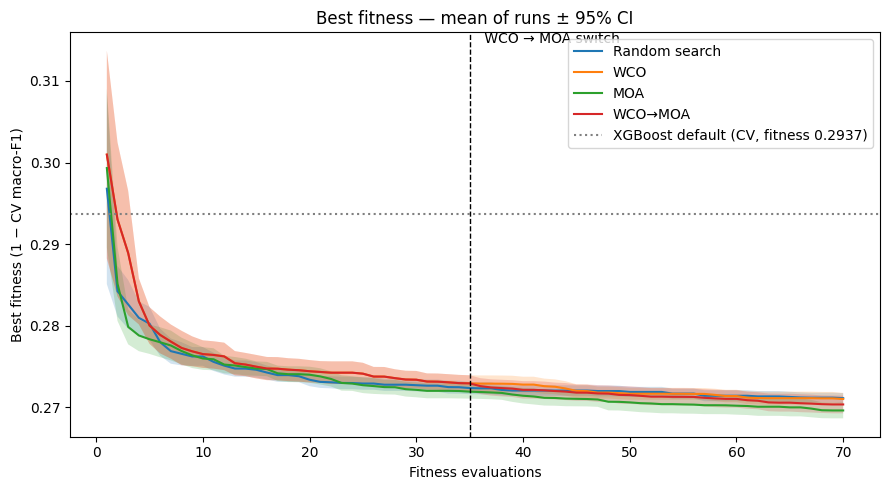

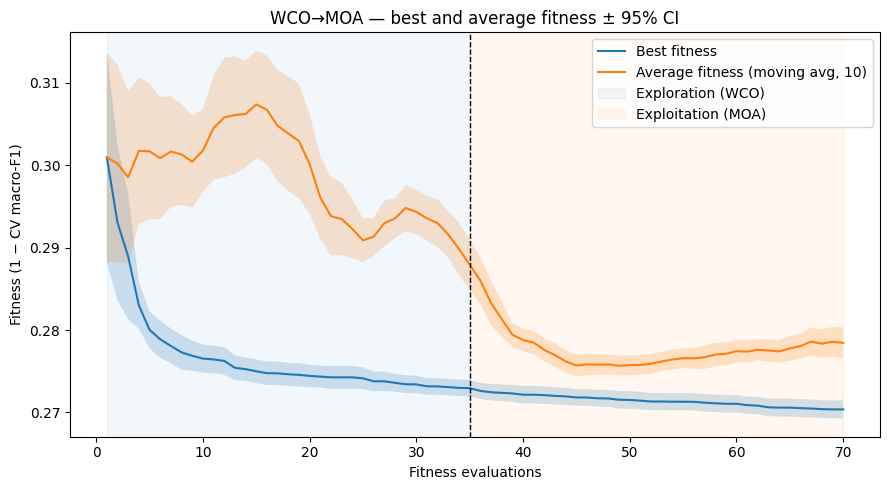

In [6]:
import matplotlib.pyplot as plt

def curves(method, key):
    A = np.array([h for h in runs.loc[runs['method'] == method, key]], dtype=float)
    if key == 'values':
        A = np.array([pd.Series(a).rolling(10, min_periods=1).mean().to_numpy() for a in A])
    mean = A.mean(0); ci = 1.96 * A.std(0, ddof=1) / np.sqrt(len(A))
    return mean, ci

switch = int(np.median([s.get('switch_eval', 0) for s in runs.loc[runs['method'] == 'wco_moa', 'stats']]))
x = np.arange(1, len(runs['best_history'].iloc[0]) + 1)

fig, ax = plt.subplots(figsize=(9, 5))
for m in METHODS:
    mean, ci = curves(m, 'best_history')
    ax.plot(x, mean, label=NAMES[m]); ax.fill_between(x, mean - ci, mean + ci, alpha=0.2)
from sklearn.model_selection import StratifiedKFold, cross_val_score
cv_def = cross_val_score(xgb(), X_tr, y_tr, cv=StratifiedKFold(3, shuffle=True, random_state=SEED), scoring='f1_macro').mean()
ax.axhline(1 - cv_def, color='gray', ls=':', label=f'XGBoost default (CV, fitness {1 - cv_def:.4f})')
ax.axvline(switch, color='k', ls='--', lw=1); ax.text(switch + 1, ax.get_ylim()[1], ' WCO → MOA switch', va='top')
ax.set(xlabel='Fitness evaluations', ylabel='Best fitness (1 − CV macro-F1)', title='Best fitness — mean of runs ± 95% CI')
ax.legend(); fig.tight_layout(); fig.savefig(f'{OUT}/convergence_best_all.png', dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
for key, lab in [('best_history', 'Best fitness'), ('values', 'Average fitness (moving avg, 10)')]:
    mean, ci = curves('wco_moa', key)
    ax.plot(x, mean, label=lab); ax.fill_between(x, mean - ci, mean + ci, alpha=0.2)
ax.axvspan(1, switch, color='tab:blue', alpha=0.06, label='Exploration (WCO)')
ax.axvspan(switch, x[-1], color='tab:orange', alpha=0.06, label='Exploitation (MOA)')
ax.axvline(switch, color='k', ls='--', lw=1)
ax.set(xlabel='Fitness evaluations', ylabel='Fitness (1 − CV macro-F1)', title='WCO→MOA — best and average fitness ± 95% CI')
ax.legend(); fig.tight_layout(); fig.savefig(f'{OUT}/convergence_hybrid.png', dpi=150); plt.show()

## 6. Final model and comparison with other ML models
Final model = WCO→MOA run with the best CV fitness. Other models are trained with standard settings on the same features.

In [7]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

best_run = runs[runs['method'] == 'wco_moa'].sort_values('best_f').iloc[0]
BEST_PARAMS = best_run['best_params']
print('Final hyperparameters (WCO→MOA, run', best_run['run'], '):', BEST_PARAMS)
json.dump(BEST_PARAMS, open(f'{OUT}/best_params.json', 'w'), indent=2)

models = {
    'Logistic regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    'KNN (k=15)':          make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15)),
    'Random forest':       RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED),
    'XGBoost default':     xgb(),
    'XGBoost + WCO→MOA':   xgb(BEST_PARAMS),
}
comp, probas = [], {}
for name, model in models.items():
    m, probas[name] = evaluate(model, X_tr, y_tr, X_te, y_te)
    comp.append({'model': name, **m})
comp = pd.DataFrame(comp).set_index('model').round(4)
comp.to_csv(f'{OUT}/model_comparison.csv')
comp

Final hyperparameters (WCO→MOA, run 13 ): {'n_estimators': 600, 'learning_rate': 0.1001588716238267, 'max_depth': 10, 'min_child_weight': 8.52155888227362, 'subsample': 1.0, 'colsample_bytree': 0.9001660787066459, 'gamma': 0.0060580363037482585, 'reg_alpha': 0.0, 'reg_lambda': 3.7716245916195352}


,accuracy,precision,recall,f1,roc_auc,cross_entropy,shannon_entropy,train_time_s,test_time_s
model,,,,,,,,,
Logistic regression,0.7275,0.7057,0.6785,0.6856,0.7830,0.5314,0.7679,0.2017,0.0295
KNN (k=15),0.7481,0.7312,0.7012,0.7096,0.8024,0.5624,0.7303,0.0838,1.3024
Random forest,0.7348,0.7517,0.6537,0.6588,0.8197,0.5369,0.8823,69.3950,0.2029
XGBoost default,0.7547,0.7356,0.7166,0.7232,0.8101,0.5094,0.6485,0.9897,0.0144
XGBoost + WCO→MOA,0.7798,0.7662,0.7424,0.7507,0.8424,0.5049,0.4857,6.0845,0.0407


### 6b. Joint model only: results on each dataset's test set
The joint text model is trained on FineFake + FakeNewsNet together; here its test predictions are split by dataset.

In [8]:
if 'dataset' in meta_te:
    def metrics_from_proba(yt, proba):
        pred = (proba >= 0.5).astype(int)
        return {'n': len(yt), 'accuracy': accuracy_score(yt, pred), 'f1': f1_score(yt, pred, average='macro'),
                'roc_auc': roc_auc_score(yt, proba)}
    per_ds = []
    for name in ['XGBoost default', 'XGBoost + WCO→MOA']:
        for ds in sorted(meta_te['dataset'].unique()):
            mask = (meta_te['dataset'] == ds).to_numpy()
            per_ds.append({'model': name, 'dataset': ds, **metrics_from_proba(y_te[mask], probas[name][mask])})
    per_ds = pd.DataFrame(per_ds).round(4)
    per_ds.to_csv(f'{OUT}/per_dataset_results.csv', index=False)
    display(per_ds)
else:
    print('Single-dataset features: per-dataset results not applicable')

,model,dataset,n,accuracy,f1,roc_auc
0,XGBoost default,fakenewsnet,4244,0.8183,0.7320,0.8285
1,XGBoost default,finefake,3060,0.6663,0.6662,0.7215
2,XGBoost + WCO→MOA,fakenewsnet,4244,0.8388,0.7557,0.8561
3,XGBoost + WCO→MOA,finefake,3060,0.6980,0.6980,0.7635


## 7. Ablation: which features matter?
The final hyperparameters trained on text only, text + image, and text + image + knowledge.

In [9]:
variants = {'A: text': X_text}
if MULTIMODAL:
    variants['B: text + image'] = np.hstack([X_text, X_img, has_im])
    variants['C: text + image + knowledge'] = X
abl = []
for name, Xv in variants.items():
    Xv = Xv.astype(np.float32)
    m, _ = evaluate(xgb(BEST_PARAMS), Xv[is_tr], y_tr, Xv[~is_tr], y_te)
    abl.append({'features': name, 'n_features': Xv.shape[1], **m})
abl = pd.DataFrame(abl).set_index('features').round(4)
abl.to_csv(f'{OUT}/ablation.csv')
abl

,n_features,accuracy,precision,recall,f1,roc_auc,cross_entropy,shannon_entropy,train_time_s,test_time_s
features,,,,,,,,,,
A: text,128,0.7798,0.7662,0.7424,0.7507,0.8424,0.5049,0.4857,6.0936,0.0415


## 8. Error analysis (final model)

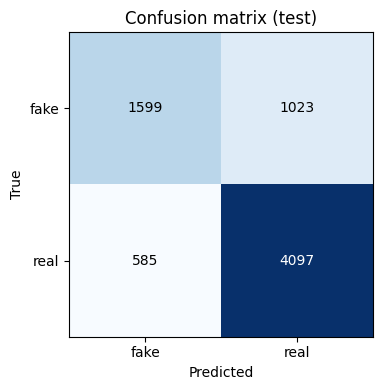

,n,accuracy,real_share
platform,,,
twitter,156,0.564,0.385
snope,1530,0.623,0.307
washingtonpost,193,0.679,0.679
reddit,511,0.769,0.358
politifact,190,0.774,0.563
cnn,493,0.840,0.909
gossipcop,4054,0.842,0.768
apnews,141,0.865,0.943
cdc_gov,36,0.972,1.000


[true=fake | pred=real | cnn ] Can You Sweat Out Toxins?Q. Is there any validity to the popular claim that one can "sweat out toxins?" If so, what "toxins" can the body sweat out? A
[true=fake | pred=real | reddit ] Football players pointing to the stadium screen
[true=fake | pred=real | snope ] At age 75, Tom Selleck finally confirmed "the rumors."
[true=fake | pred=real | gossipcop ] Ellen DeGeneres gives waitress $10,000: Server gets big tip after picking up soldiers' tab
[true=real | pred=fake | washingtonpost ] This teen got vaccinated against his mother's wishes. Now, he'll testify before Congress.Ethan Lindenberger, 18, of Norwalk, Ohio, decided to get vacc


In [10]:
proba = probas['XGBoost + WCO→MOA']
pred = (proba >= 0.5).astype(int)
cm = confusion_matrix(y_te, pred)

fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(cm, cmap='Blues')
for (i, j), v in np.ndenumerate(cm):
    ax.text(j, i, v, ha='center', va='center', color='white' if v > cm.max() / 2 else 'black')
ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=['fake', 'real'], yticklabels=['fake', 'real'],
       xlabel='Predicted', ylabel='True', title='Confusion matrix (test)')
fig.tight_layout(); fig.savefig(f'{OUT}/confusion_matrix.png', dpi=150); plt.show()

err = meta_te.assign(true=y_te, pred=pred, correct=(pred == y_te))
FINE = {0: 'real', 1: 'text–image inconsistency', 2: 'content–knowledge inconsistency',
        3: 'text-based fake', 4: 'image-based fake', 5: 'others'}
by_platform = err.groupby('platform').agg(n=('correct', 'size'), accuracy=('correct', 'mean'),
                                          real_share=('true', 'mean')).sort_values('accuracy').round(3)
by_platform.to_csv(f'{OUT}/errors_by_platform.csv'); display(by_platform)
if 'fine_label' in err:
    by_fine = err.groupby('fine_label').agg(n=('correct', 'size'), accuracy=('correct', 'mean')).round(3)
    by_fine.index = by_fine.index.map(FINE)
    by_fine.to_csv(f'{OUT}/errors_by_fine_label.csv'); display(by_fine)
if 'has_image' in err:
    display(err.groupby('has_image').agg(n=('correct', 'size'), accuracy=('correct', 'mean')).round(3))

wrong = err[~err['correct']].sample(min(5, (~err['correct']).sum()), random_state=SEED)
for _, r in wrong.iterrows():
    kind = FINE[r.fine_label] if 'fine_label' in err else ''
    print(f"[true={'real' if r.true else 'fake'} | pred={'real' if r.pred else 'fake'} | {r.platform} {kind}] {r.text_clean[:150]}")

## 9. Demo: predict any news text (joint text model)
New text → same cleaning → same sentence encoder → same PCA → final XGBoost → probability of being fake.
(Needs Internet ON to download the encoder.)

In [11]:
if os.path.exists(f'{FEAT}/pca.pkl') and not MULTIMODAL:
    !pip install -q sentence-transformers
    import re, html, joblib
    from sentence_transformers import SentenceTransformer
    encoder = SentenceTransformer('all-mpnet-base-v2', device=DEV); encoder.max_seq_length = 384
    pca_joint = joblib.load(f'{FEAT}/pca.pkl')
    detector = models['XGBoost + WCO→MOA']

    def clean_news(t):
        t = html.unescape(str(t))
        t = re.sub(r'<[^>]+>', ' ', t)
        for k, v in {'\u2019': "'", '\u2018': "'", '\u201c': '"', '\u201d': '"', '\u2013': '-', '\u2014': '-'}.items():
            t = t.replace(k, v)
        t = re.sub(r'https?://\S+|www\.\S+', ' [URL] ', t)
        t = re.sub(r'@\w+', ' ', t)
        t = re.sub(r'#(\w+)', r'\1', t)
        return re.sub(r'\s+', ' ', t).strip()

    def predict(text):
        v = encoder.encode([clean_news(text)], normalize_embeddings=True)
        p_real = float(detector.predict_proba(pca_joint.transform(v).astype(np.float32))[0, 1])
        verdict = 'REAL' if p_real >= 0.5 else 'FAKE'
        print(f'{verdict:4s}  (P(fake) = {1 - p_real:.2f})  ←  {text}')
        return verdict, 1 - p_real

    demo = []
    for t in ['Scientists confirm that drinking bleach cures the flu, doctors stunned',
              'The Federal Reserve raised interest rates by a quarter point on Wednesday',
              'BREAKING: Famous actor secretly replaced by body double, insiders reveal',
              'City council approves new budget for public schools after long debate']:
        v, pf = predict(t); demo.append({'input': 'new text', 'text': t, 'pred': v, 'p_fake': round(pf, 4)})
    pd.DataFrame(demo).to_csv(f'{OUT}/demo_predictions.csv', index=False)
else:
    print('Demo only for the joint text model (features with pca.pkl)')

FAKE  (P(fake) = 0.52)  ←  Scientists confirm that drinking bleach cures the flu, doctors stunned
REAL  (P(fake) = 0.30)  ←  The Federal Reserve raised interest rates by a quarter point on Wednesday
FAKE  (P(fake) = 0.90)  ←  BREAKING: Famous actor secretly replaced by body double, insiders reveal
REAL  (P(fake) = 0.09)  ←  City council approves new budget for public schools after long debate


## 10. Files produced

In [12]:
for f in sorted(os.listdir(OUT)):
    print(f'{f:32s} {os.path.getsize(f"{OUT}/{f}") / 1e3:8.1f} KB')

ablation.csv                          0.2 KB
best_params.json                      0.3 KB
confusion_matrix.png                 21.5 KB
convergence_best_all.png            104.9 KB
convergence_hybrid.png              108.8 KB
demo_predictions.csv                  0.4 KB
errors_by_platform.csv                0.2 KB
model_comparison.csv                  0.5 KB
per_dataset_results.csv               0.3 KB
per_run_results.csv                  23.9 KB
results_table.csv                     0.9 KB
stats_cv_f1.csv                       0.3 KB
stats_summary.json                    0.9 KB
stats_test_f1.csv                     0.3 KB
